# Ejercicio 2 Predicción de precios de Airbnb en Toronto

Grupo 14. Toronto corresponde al grupo 14 según la planilla de ciudades.

Usamos Detailed Listings de Inside Airbnb, captura del 16/09/2026. La unidad es un anuncio; el objetivo `price` representa el precio por noche publicado en la captura, no ingresos realizados ni un precio constante durante todo el año. El archivo incluye cotizaciones que pueden corresponder a estancias mensuales y descuentos: documentamos esta limitación. Verificamos la moneda dentro de `price_quote_raw`, **solo para describirla**, sin usar esa columna ni ninguna cotización como predictor.

Fuente: https://insideairbnb.com/get-the-data/. URL exacta, fecha y hash en `fuente_airbnb.json`. Se comparan regresión lineal múltiple y Random Forest Regressor, que permite relaciones no lineales e interacciones aprendidas entre variables.

## Integrantes

- Calandria, Alén Santiago (padrón: 112103).
- Szinvelski, Sol Yohara (padrón: 112985).
- Garay Alvarado, Gustavo Alfredo (padrón: intercambio-02).
- Sosa, Matias (padrón: 113352).
- Fontanals Layos, Oriol (padrón: intercambio-03).

In [1]:
from pathlib import Path
import json,platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn,joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split,GridSearchCV,KFold
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.inspection import permutation_importance
ROOT=Path.cwd()
if not (ROOT/'datos/airbnb').exists() and (ROOT.parent/'datos/airbnb').exists():ROOT=ROOT.parent
OUT=ROOT/'resultados/ej2';OUT.mkdir(parents=True,exist_ok=True)
raw=pd.read_csv(ROOT/'datos/airbnb/toronto_listings_2026-09-16.csv.gz')
assert raw['id'].is_unique
price=pd.to_numeric(raw['price'].astype(str).str.replace(r'[^0-9.-]','',regex=True),errors='coerce')
valid_price=price.notna()&np.isfinite(price)&price.gt(0)
data=raw.loc[valid_price].copy();data['price_numeric']=price.loc[valid_price]
train_idx,test_idx=train_test_split(data.index,test_size=.2,random_state=42)
train=data.loc[train_idx].copy();test=data.loc[test_idx].copy()
assert set(train.id).isdisjoint(test.id)
currency=raw['price_quote_raw'].dropna().map(lambda s:json.loads(s).get('quote',{}).get('currency')).fillna('Sin moneda informada').value_counts().to_dict()
print('Origen',raw.shape,'Objetivo válido',len(data),'Train',len(train),'Test',len(test),'Monedas:',currency)
quality=dict(source_rows=len(raw),source_columns=raw.shape[1],invalid_target=int((~valid_price).sum()),
    modeling_rows=len(data),train_rows=len(train),test_rows=len(test),currencies=currency)
pd.DataFrame(dict(id=data.id,split=np.where(data.index.isin(train_idx),'train','test'))).to_csv(OUT/'particion.csv',index=False)
def savefig(name):
    plt.tight_layout();plt.savefig(ROOT/'figuras'/f'ej2_{name}.png',dpi=150,bbox_inches='tight');plt.show()

Origen (22050, 90) Objetivo válido 16760 Train 13408 Test 3352 Monedas: {'CAD': 17917, 'Sin moneda informada': 218}


## Preparación sin filtrar información del test

Primero se separa 80% para entrenamiento y 20% para prueba. El EDA que guía decisiones usa exclusivamente entrenamiento. Los anuncios sin precio positivo no sirven como ejemplos supervisados: se informa su cantidad y no se inventa su etiqueta.

Se excluyen identificadores, nombres, textos libres, URLs, todas las columnas `price_quote_*` y estimaciones de ingresos. Estas últimas pueden contener el objetivo o derivarse de él. `bathrooms` está vacío en esta captura; extraemos el número desde `bathrooms_text` y distinguimos baños compartidos. Contamos amenities y derivamos antigüedad del anfitrión respecto a la fecha fija de captura. Aplicamos log1p a conteos muy asimétricos, conservando los extremos de precio para no mejorar artificialmente el test.

Dentro de cada fold se imputan numéricas con mediana y categorías con “Sin dato”. One-Hot agrupa categorías infrecuentes con un umbral fijado de antemano. La regresión lineal usa escalado y una categoría de referencia. RF no necesita escalado, pero comparte el mismo preprocesamiento para facilitar la comparación.

Atípicos superiores IQR, train: 547 umbral CAD 648.14625 se conservan


,proporcion_faltantes_train
instant_bookable,1.000000
host_response_rate_numeric,1.000000
host_years,1.000000
review_scores_rating,0.179072
beds,0.017229
bathrooms_numeric,0.002685
log_minimum_nights,0.002312
bedrooms,0.000373
accommodates,0.000000
longitude,0.000000


,precio_CAD
count,13408.000000
mean,241.212983
std,324.478492
min,17.310000
25%,90.440000
50%,162.790000
75%,313.522500
95%,601.000000
99%,1153.790000
max,9049.100000


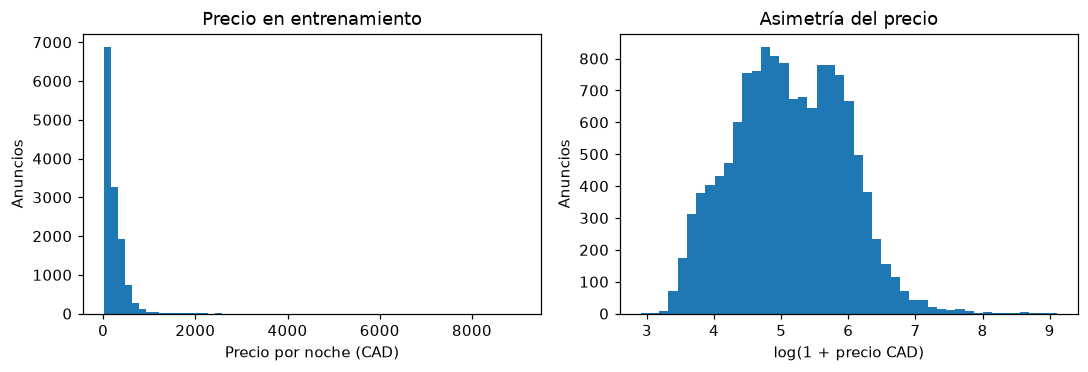

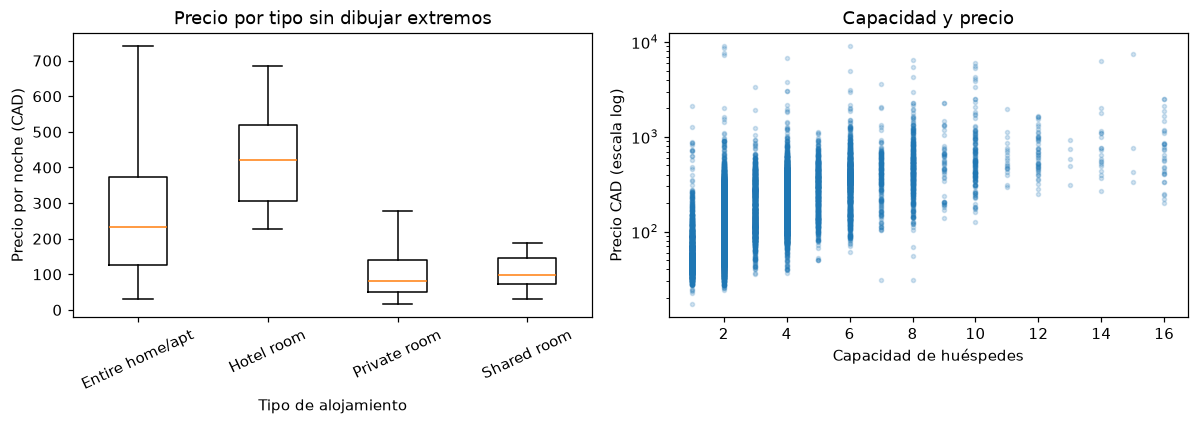

In [2]:
numeric=['accommodates','bedrooms','beds','bathrooms_numeric','latitude','longitude','amenities_count',
    'log_minimum_nights','log_reviews','review_scores_rating','host_years','host_response_rate_numeric']
categorical=['room_type','property_type','neighbourhood_cleansed','host_is_superhost','instant_bookable','shared_bath']
def features(frame):
    z=frame.copy()
    z['bathrooms_numeric']=pd.to_numeric(z['bathrooms_text'].str.extract(r'(\d+(?:\.\d+)?)',expand=False),errors='coerce')
    half=z['bathrooms_text'].str.contains('half',case=False,na=False);z.loc[half,'bathrooms_numeric']=.5
    z['shared_bath']=np.where(z['bathrooms_text'].isna(),'Sin dato',np.where(z['bathrooms_text'].str.contains('shared',case=False,na=False),'Si','No'))
    z['amenities_count']=z['amenities'].map(lambda s:len(json.loads(s)) if isinstance(s,str) and s.strip().startswith('[') else np.nan)
    z['log_minimum_nights']=np.log1p(pd.to_numeric(z['minimum_nights'],errors='coerce').clip(lower=0))
    z['log_reviews']=np.log1p(pd.to_numeric(z['number_of_reviews'],errors='coerce').clip(lower=0))
    z['host_years']=(pd.Timestamp('2026-09-16')-pd.to_datetime(z['host_since'],errors='coerce')).dt.days/365.25
    z.loc[z['host_years']<0,'host_years']=np.nan
    z['host_response_rate_numeric']=pd.to_numeric(z['host_response_rate'].astype('string').str.rstrip('%'),errors='coerce')/100
    for col in numeric:z[col]=pd.to_numeric(z[col],errors='coerce')
    return z[numeric+categorical].replace([np.inf,-np.inf],np.nan)
X_train=features(train);X_test=features(test);y_train=train['price_numeric'];y_test=test['price_numeric']
display(X_train.isna().mean().sort_values(ascending=False).to_frame('proporcion_faltantes_train'))
display(y_train.describe(percentiles=[.25,.5,.75,.95,.99]).to_frame('precio_CAD'))
q1,q3=y_train.quantile([.25,.75]);upper=float(q3+1.5*(q3-q1));outliers=int(y_train.gt(upper).sum())
print('Atípicos superiores IQR, train:',outliers,'umbral CAD',upper,'se conservan')
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].hist(y_train,bins=60);axes[0].set(xlabel='Precio por noche (CAD)',ylabel='Anuncios',title='Precio en entrenamiento')
axes[1].hist(np.log1p(y_train),bins=45);axes[1].set(xlabel='log(1 + precio CAD)',ylabel='Anuncios',title='Asimetría del precio');savefig('precio')
fig,axes=plt.subplots(1,2,figsize=(11,4))
types=sorted(train.room_type.dropna().unique())
axes[0].boxplot([train.loc[train.room_type.eq(t),'price_numeric'] for t in types],tick_labels=types,showfliers=False)
axes[0].tick_params(axis='x',rotation=25);axes[0].set(xlabel='Tipo de alojamiento',ylabel='Precio por noche (CAD)',title='Precio por tipo sin dibujar extremos')
axes[1].scatter(train.accommodates,y_train,s=7,alpha=.2);axes[1].set_yscale('log');axes[1].set(xlabel='Capacidad de huéspedes',ylabel='Precio CAD (escala log)',title='Capacidad y precio');savefig('relaciones')
for name,x,y in [('train',X_train,y_train),('test',X_test,y_test)]:
    saved=x.copy();saved.insert(0,'id',data.loc[x.index,'id']);saved['price']=y
    saved.to_csv(ROOT/'datos/procesados'/f'airbnb_{name}.csv',index=False)
prep=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric),
    ('cat',Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='Sin dato')),
        ('onehot',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=20,drop='first',sparse_output=False))]),categorical)])
linear=Pipeline([('prep',prep),('model',LinearRegression())])
from sklearn.base import clone
forest=Pipeline([('prep',clone(prep)),('model',RandomForestRegressor(n_estimators=250,random_state=42,n_jobs=4))])

## Entrenamiento y validación cruzada

La regresión lineal estima una suma ponderada de las variables transformadas. Random Forest promedia árboles y aprende relaciones no lineales. Se ajustan profundidad, hoja mínima y fracción de variables con tres folds únicamente sobre entrenamiento. Elegimos por RMSE, que penaliza errores grandes en la moneda del precio. MAE facilita interpretar el error absoluto típico y R² compara contra la media del conjunto evaluado. También mostramos MSE, en CAD al cuadrado.

El test no interviene en la búsqueda. Se evalúa una vez después de fijar hiperparámetros. El recorte a cero de cualquier predicción negativa se define antes de evaluar y se aplica a ambos modelos por el dominio no negativo del precio. Los datos de anuncios de un mismo anfitrión pueden caer en ambos conjuntos: esta partición mide anuncios del mismo universo, no nuevos anfitriones ni períodos futuros.

CV Random Forest: 8 configuraciones, 3 folds
Mejores parámetros {'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 5} RMSE CV 259.4153992808112
{'modelo': 'Regresion lineal', 'conjunto': 'train', 'MSE': 72194.89512154415, 'RMSE': 268.6910774877799, 'MAE': 97.26124678268832, 'R2': 0.3142480499370275, 'predicciones_negativas_recortadas': 679}
{'modelo': 'Regresion lineal', 'conjunto': 'test', 'MSE': 68277.12360260641, 'RMSE': 261.29891619102904, 'MAE': 94.83557920397477, 'R2': 0.3352695828187199, 'predicciones_negativas_recortadas': 190}
{'modelo': 'Random Forest', 'conjunto': 'train', 'MSE': 47726.31329105652, 'RMSE': 218.46352851461617, 'MAE': 60.27343312832647, 'R2': 0.546665836226256, 'predicciones_negativas_recortadas': 0}
{'modelo': 'Random Forest', 'conjunto': 'test', 'MSE': 64866.731229728495, 'RMSE': 254.68948001385627, 'MAE': 77.15429729586461, 'R2': 0.36847238084474065, 'predicciones_negativas_recortadas': 0}
Fracción de test con anfitrión presen

,modelo,conjunto,MSE,RMSE,MAE,R2,predicciones_negativas_recortadas
0,Regresion lineal,train,72194.895122,268.691077,97.261247,0.314248,679
1,Regresion lineal,test,68277.123603,261.298916,94.835579,0.335270,190
2,Random Forest,train,47726.313291,218.463529,60.273433,0.546666,0
3,Random Forest,test,64866.731230,254.689480,77.154297,0.368472,0


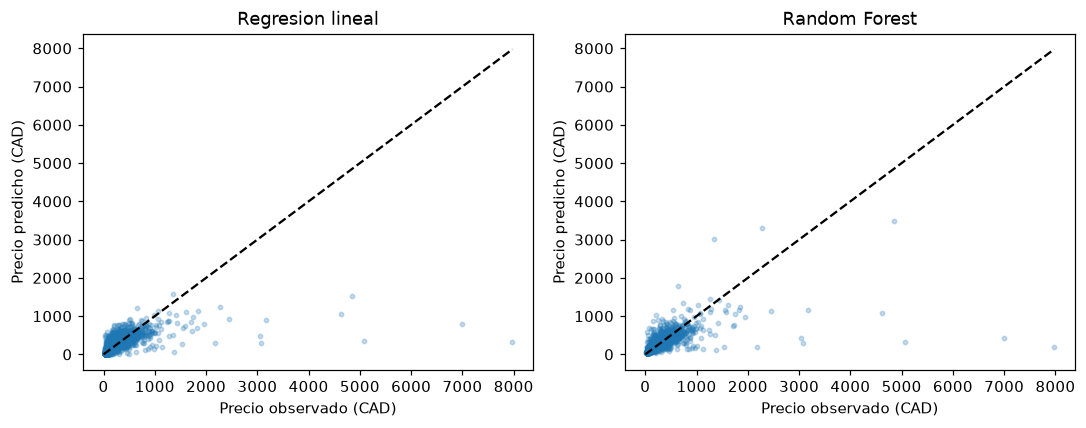

In [3]:
linear.fit(X_train,y_train)
grid={'model__max_depth':[16,None],'model__min_samples_leaf':[2,5],'model__max_features':[.7,1.]}
search=GridSearchCV(forest,grid,scoring='neg_root_mean_squared_error',cv=KFold(n_splits=3,shuffle=True,random_state=42),n_jobs=1,refit=True,return_train_score=True)
print('CV Random Forest: 8 configuraciones, 3 folds',flush=True)
search.fit(X_train,y_train)
pd.DataFrame(search.cv_results_).to_csv(OUT/'busqueda_rf.csv',index=False)
print('Mejores parámetros',search.best_params_,'RMSE CV',-search.best_score_,flush=True)
models={'Regresion lineal':linear,'Random Forest':search.best_estimator_}
metrics=[];predictions={}
for name,model in models.items():
    for split,x,y in [('train',X_train,y_train),('test',X_test,y_test)]:
        raw_pred=model.predict(x);pred=np.maximum(0,raw_pred)
        row=dict(modelo=name,conjunto=split,MSE=float(mean_squared_error(y,pred)),RMSE=float(np.sqrt(mean_squared_error(y,pred))),
            MAE=float(mean_absolute_error(y,pred)),R2=float(r2_score(y,pred)),predicciones_negativas_recortadas=int((raw_pred<0).sum()))
        metrics.append(row);print(row,flush=True)
        if split=='test':predictions[name]=pred
    joblib.dump(model,ROOT/'modelos'/('ej2_lineal.joblib' if name=='Regresion lineal' else 'ej2_random_forest.joblib'),compress=3)
table=pd.DataFrame(metrics);display(table);table.to_csv(OUT/'metricas.csv',index=False)
winner=table.loc[table.conjunto.eq('test')].sort_values('RMSE').iloc[0]['modelo']
pred_frame=pd.DataFrame({'id':test.id,'price':y_test,**predictions});pred_frame.to_csv(OUT/'predicciones_test.csv',index=False)
host_overlap=float(test.host_id.isin(train.host_id).mean())
print('Fracción de test con anfitrión presente en train:',host_overlap)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,(name,pred) in zip(axes,predictions.items()):
    ax.scatter(y_test,pred,s=8,alpha=.25);mx=max(y_test.max(),pred.max());ax.plot([0,mx],[0,mx],color='black',linestyle='--')
    ax.set(xlabel='Precio observado (CAD)',ylabel='Precio predicho (CAD)',title=name)
savefig('predicciones')

## Variables influyentes e interpretación

Los coeficientes de la regresión lineal se interpretan manteniendo las demás variables constantes. Las numéricas están estandarizadas: un coeficiente representa el cambio de precio por una desviación estándar de esa variable transformada; las dummies se comparan con una categoría de referencia. Correlación entre predictores y categorías poco frecuentes puede volver inestables los coeficientes. No son efectos causales.

Para RF calculamos importancia por permutación en una muestra fija de entrenamiento para describir dependencia predictiva del modelo sin volver a usar el test para seleccionarlo. No es una estimación independiente: variables correlacionadas pueden repartirse o esconder importancia. La métrica es aumento de RMSE al desordenar cada predictor.

,variable,coeficiente,abs
30,cat__property_type_Room in boutique hotel,558.302941,558.302941
44,cat__neighbourhood_cleansed_Black Creek,518.823883,518.823883
121,cat__neighbourhood_cleansed_Princess-Rosethorn,503.728484,503.728484
94,cat__neighbourhood_cleansed_Lawrence Park South,354.417260,354.417260
119,cat__neighbourhood_cleansed_Playter Estates-Danforth,310.258672,310.258672
82,cat__neighbourhood_cleansed_Humbermede,286.516472,286.516472
63,cat__neighbourhood_cleansed_Downsview-Roding-CFB,279.180737,279.180737
35,cat__neighbourhood_cleansed_Annex,253.288955,253.288955
83,cat__neighbourhood_cleansed_Humewood-Cedarvale,239.582576,239.582576
69,cat__neighbourhood_cleansed_Eringate-Centennial-West Deane,229.778916,229.778916


,variable,aumento_RMSE,std
7,log_minimum_nights,48.405298,6.517645
0,accommodates,41.606101,1.702305
3,bathrooms_numeric,21.271631,0.098716
4,latitude,15.357297,0.720409
14,neighbourhood_cleansed,14.689234,1.214479
5,longitude,12.296882,0.882952
6,amenities_count,11.116471,1.116011
8,log_reviews,8.623978,0.471457
1,bedrooms,6.709237,0.452034
12,room_type,5.687020,0.238416


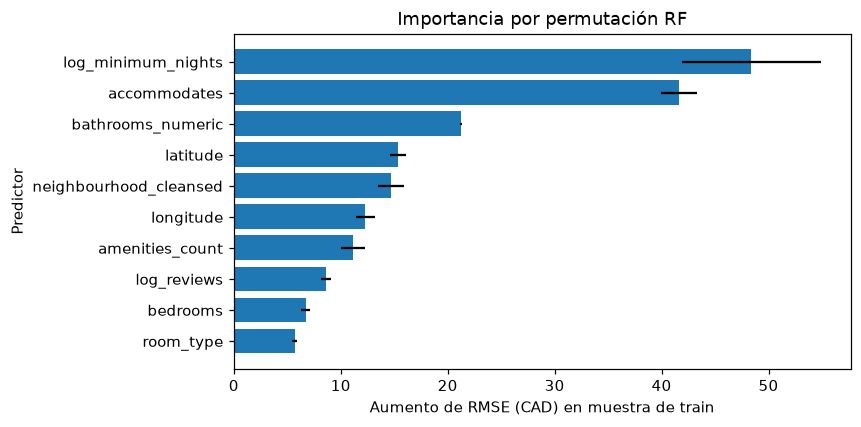

In [4]:
names=linear.named_steps['prep'].get_feature_names_out()
coef=pd.DataFrame({'variable':names,'coeficiente':linear.named_steps['model'].coef_});coef['abs']=coef.coeficiente.abs();coef=coef.sort_values('abs',ascending=False)
coef.to_csv(OUT/'coeficientes_lineal.csv',index=False);display(coef.head(15))
idx=np.random.default_rng(42).choice(len(X_train),size=min(2500,len(X_train)),replace=False)
importance=permutation_importance(models['Random Forest'],X_train.iloc[idx],y_train.iloc[idx],n_repeats=3,
    scoring='neg_root_mean_squared_error',random_state=42,n_jobs=1)
imp=pd.DataFrame({'variable':X_train.columns,'aumento_RMSE':importance.importances_mean,'std':importance.importances_std}).sort_values('aumento_RMSE',ascending=False)
imp.to_csv(OUT/'importancia_rf.csv',index=False);display(imp.head(10))
fig,ax=plt.subplots(figsize=(8,4));top=imp.head(10).iloc[::-1];ax.barh(top.variable,top.aumento_RMSE,xerr=top['std']);ax.set(xlabel='Aumento de RMSE (CAD) en muestra de train',ylabel='Predictor',title='Importancia por permutación RF');savefig('importancias')
result=dict(quality=quality,best_rf_params=search.best_params_,cv_rmse_rf=float(-search.best_score_),metrics=metrics,
    winner=winner,host_overlap_test=host_overlap,train_upper_iqr=upper,train_high_outliers=outliers,
    important_rf=imp.head(10).to_dict(orient='records'),linear_coefficients=coef.head(15).to_dict(orient='records'),
    features=numeric+categorical,versions=dict(sklearn=sklearn.__version__,numpy=np.__version__,pandas=pd.__version__),
    currency='CAD',prediction_postprocess='max(0,prediction)',snapshot='2026-09-16')
(OUT/'resultados.json').write_text(json.dumps(result,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')

## Conclusiones

Se modelaron 16760 anuncios con precio positivo de los 22050 originales. Se excluyeron 5290 sin objetivo válido, por lo que las conclusiones no abarcan todos los anuncios.

- Regresion lineal en train: RMSE 268.69 CAD, MAE 97.26 CAD, R² 0.314.
- Regresion lineal en test: RMSE 261.30 CAD, MAE 94.84 CAD, R² 0.335.
- Random Forest en train: RMSE 218.46 CAD, MAE 60.27 CAD, R² 0.547.
- Random Forest en test: RMSE 254.69 CAD, MAE 77.15 CAD, R² 0.368.

Según RMSE de prueba elegiríamos **Random Forest** entre estas dos alternativas. Se debe considerar también MAE y la brecha train/test; RMSE es sensible a los anuncios de precio muy alto, que conservamos. No representa una garantía para otra fecha o ciudad.

El 43.6% de anuncios de test comparte anfitrión con entrenamiento. Una evaluación futura debería separar anfitriones o períodos. Las cotizaciones pueden reflejar descuentos y fechas diferentes; faltaría evaluar esa heterogeneidad antes de utilizar el modelo para fijar precios reales.

Para cargar los modelos guardados, se deben construir primero las variables con `features` de este notebook y recortar predicciones negativas a cero, tal como en la evaluación.

## Aclaración de esta captura

`host_since`, `host_response_rate` e `instant_bookable` están completamente vacías. Por eso `host_years`, `host_response_rate_numeric` e `instant_bookable` son descartadas por el imputador, como indican sus advertencias; no se inventa una mediana para ellas ni se afirma que aporten señal. La función conserva esas columnas para hacer explícito el esquema de entrada, pero no llegan al estimador ajustado. Las categorías desconocidas del test se codifican con la categoría infrecuente cuando existe; no se reentrena el encoder mirando test.

La interpretación de coeficientes se refiere al modelo lineal previo al recorte de predicciones a cero. Hubo 190 predicciones negativas en test; ese límite también evidencia que la forma lineal no respeta por sí sola el dominio del precio.
